# 6. Evaluación estadística

- **Discriminación:** ROC AUC y PR AUC.
- **Probabilística:** log loss, Brier, ECE (15 intervalos uniformes; también por cuantiles) y
  curvas de calibración.
- **Umbral fijo:** accuracy, precision, recall, F1 y matriz de confusión, con el umbral que
  maximiza F1 en **validación** (nunca en prueba).
- **Negocio:** lift y ganancia acumulada por deciles.
- **Inferencia:** IC 95 % por bootstrap de Poisson, DeLong para AUC correlacionadas (mismas filas
  de prueba) y McNemar para clasificaciones. Las comparaciones múltiples se ajustan con Holm.

La variación entre semillas (media, DE, IC t) mide la inestabilidad del entrenamiento; el
bootstrap mide la incertidumbre por la muestra de prueba. Son fuentes distintas y se reportan
por separado.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else str(Path.cwd() / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from statsmodels.stats.multitest import multipletests
from ctr.nbutils import setup, savefig, show, load_preds, SERIES, MUTED, FRAMEWORK_COLOR
from ctr import data, metrics as M
from ctr.bench import read_jsonl

cfg, RES, FIG = setup()
runs = pd.concat([read_jsonl(RES / "runs_sklearn.jsonl"), read_jsonl(RES / "runs_spark.jsonl")], ignore_index=True)
if "omitida" in runs:
    runs = runs[runs["omitida"].isna()].copy()
runs["n"] = runs["n"].astype(int)
_, te = data.eval_sets(cfg)
yte = te["click"].to_numpy()
assert np.array_equal(pd.read_parquet(RES / "test_ids.parquet")["id"].to_numpy(), te["id"].to_numpy())

Perfil: colab  |  resultados en: /content/deep-learning-01-ctr-mlp/results


## 6.1 Tabla comparativa (media, DE e IC 95 % entre semillas)

In [2]:
MET = ["roc_auc", "pr_auc", "log_loss", "brier", "ece", "accuracy", "precision", "recall", "f1"]
tab = M.summarize_runs(runs, ["framework", "model", "encoding", "n"], MET + ["train_s", "predict_s", "train_peak_mb"])
tab = tab.sort_values(["framework", "encoding", "model", "n"])
tab.to_csv(RES / "tabla_comparativa_completa.csv", index=False)
show(tab[["framework", "model", "encoding", "n", "n_semillas", "roc_auc_media", "roc_auc_sd", "roc_auc_ic",
          "pr_auc_media", "log_loss_media", "brier_media", "ece_media", "f1_media"]], 80)

,framework,model,encoding,n,n_semillas,roc_auc_media,roc_auc_sd,roc_auc_ic,pr_auc_media,log_loss_media,brier_media,ece_media,f1_media
0,sklearn,hgb,freq,100000,5,0.7128,0.0000,"[0.7128, 0.7128]",0.3388,0.4132,0.1284,0.0066,0.3962
1,sklearn,hgb,freq,1000000,5,0.7254,0.0010,"[0.7241, 0.7266]",0.3533,0.4076,0.1268,0.0066,0.4092
2,sklearn,hgb,freq,10000000,1,0.7251,NaN,n=1,0.3563,0.4086,0.1269,0.0160,0.4122
6,sklearn,mlp,freq,100000,5,0.6630,0.0061,"[0.6554, 0.6705]",0.2903,0.4328,0.1336,0.0186,0.3472
7,sklearn,mlp,freq,1000000,5,0.6826,0.0043,"[0.6773, 0.6879]",0.3140,0.4254,0.1315,0.0153,0.3613
8,sklearn,mlp,freq,10000000,1,0.6717,NaN,n=1,0.3114,0.4401,0.1329,0.0261,0.3590
15,sklearn,sgd,freq,100000,5,0.6541,0.0027,"[0.6507, 0.6575]",0.2777,0.4333,0.1343,0.0190,0.3461
16,sklearn,sgd,freq,1000000,5,0.6516,0.0021,"[0.6490, 0.6543]",0.2621,0.4355,0.1351,0.0132,0.3513
17,sklearn,sgd,freq,10000000,1,0.6409,NaN,n=1,0.2485,0.4436,0.1380,0.0289,0.3358
9,sklearn,mlp,hash,100000,5,0.7171,0.0007,"[0.7162, 0.7180]",0.3460,0.4110,0.1278,0.0111,0.3914


## 6.2 Conjunto de comparación

Para comparar entornos se toma el **mayor tamaño de entrenamiento común** a ambos con la misma
codificación (frecuencia) y, dentro de cada entorno, el MLP y sus líneas base. También se
incluye el mejor modelo de scikit-learn en general.

In [3]:
seed0 = cfg["seed_base"]
r0 = runs[(runs["seed"] == seed0) & runs["pred_file"].notna()].copy()
common = sorted(set(r0[(r0.framework == "sklearn") & (r0.encoding == "freq")]["n"]) &
                set(r0[(r0.framework == "spark") & (r0.encoding == "freq")]["n"]))
N_CMP = max(common)
print(f"Tamaño común de comparación: {N_CMP:,}")

def pick(fw, model, enc, n):
    g = r0[(r0.framework == fw) & (r0.model == model) & (r0.encoding == enc) & (r0.n == n)]
    return None if g.empty else g.iloc[0]

cands = {
    "sk MLP freq": pick("sklearn", "mlp", "freq", N_CMP), "sk HGB freq": pick("sklearn", "hgb", "freq", N_CMP),
    "sk SGD freq": pick("sklearn", "sgd", "freq", N_CMP), "spark MLP freq": pick("spark", "mlp", "freq", N_CMP),
    "spark GBT freq": pick("spark", "gbt", "freq", N_CMP), "spark LR freq": pick("spark", "lr", "freq", N_CMP),
}
# P3 se responde con cada modelo en su MEJOR codificación y al mismo tamaño: MLP y SGD con hashing,
# HGB con target encoding (HGB no admite la matriz dispersa del hashing).
sk_ok = r0[r0.framework == "sklearn"]
both = sorted(set(sk_ok[(sk_ok.model == "mlp") & (sk_ok.encoding == "hash")]["n"]) &
              set(sk_ok[(sk_ok.model == "hgb") & (sk_ok.encoding == "target")]["n"]))
N_BEST = max(both) if both else None
if N_BEST:
    cands.update({"sk MLP hash": pick("sklearn", "mlp", "hash", N_BEST),
                  "sk HGB target": pick("sklearn", "hgb", "target", N_BEST),
                  "sk SGD hash": pick("sklearn", "sgd", "hash", N_BEST)})
    print(f"Tamaño para comparar mejores configuraciones: {N_BEST:,}")
sp_h = r0[(r0.framework == "spark") & (r0.encoding == "hash")]
if len(sp_h):
    n_sh = int(sp_h["n"].max())
    cands.update({"spark MLP hash": pick("spark", "mlp", "hash", n_sh), "spark LR hash": pick("spark", "lr", "hash", n_sh),
                  "sk MLP hash (mismo n que Spark)": pick("sklearn", "mlp", "hash", n_sh)})
cands = {k: v for k, v in cands.items() if v is not None}
P = {k: load_preds(RES, v["pred_file"]) for k, v in cands.items()}
THR = {k: float(v["threshold"]) for k, v in cands.items()}
list(cands)

Tamaño común de comparación: 10,000,000
Tamaño para comparar mejores configuraciones: 10,000,000


['sk MLP freq',
 'sk HGB freq',
 'sk SGD freq',
 'spark MLP freq',
 'spark GBT freq',
 'spark LR freq',
 'sk MLP hash',
 'sk HGB target',
 'sk SGD hash',
 'spark MLP hash',
 'spark LR hash',
 'sk MLP hash (mismo n que Spark)']

## 6.3 IC por bootstrap (prueba)

In [4]:
boots = []
for k, p in P.items():
    b = M.bootstrap_ci(yte, p, cfg["bootstrap"], seed=seed0)
    b["modelo"] = k
    b["puntual"] = [M.all_metrics(yte, p, THR[k])[m] for m in b["metrica"]]
    boots.append(b)
boots = pd.concat(boots)[["modelo", "metrica", "puntual", "ic_inf", "ic_sup", "sd_boot"]]
boots.to_csv(RES / "bootstrap_ic.csv", index=False)
show(boots, 60)

,modelo,metrica,puntual,ic_inf,ic_sup,sd_boot
0,sk MLP freq,roc_auc,0.6717,0.6711,0.6724,0.0003
1,sk MLP freq,pr_auc,0.3114,0.3103,0.3123,0.0005
2,sk MLP freq,log_loss,0.4401,0.4394,0.4407,0.0004
3,sk MLP freq,brier,0.1329,0.1327,0.1332,0.0001
0,sk HGB freq,roc_auc,0.7251,0.7245,0.7257,0.0003
1,sk HGB freq,pr_auc,0.3563,0.3553,0.3574,0.0005
2,sk HGB freq,log_loss,0.4086,0.4080,0.4091,0.0003
3,sk HGB freq,brier,0.1269,0.1267,0.1271,0.0001
0,sk SGD freq,roc_auc,0.6409,0.6403,0.6416,0.0004
1,sk SGD freq,pr_auc,0.2485,0.2477,0.2494,0.0004


## 6.4 Curvas ROC, PR, calibración, lift y ganancia

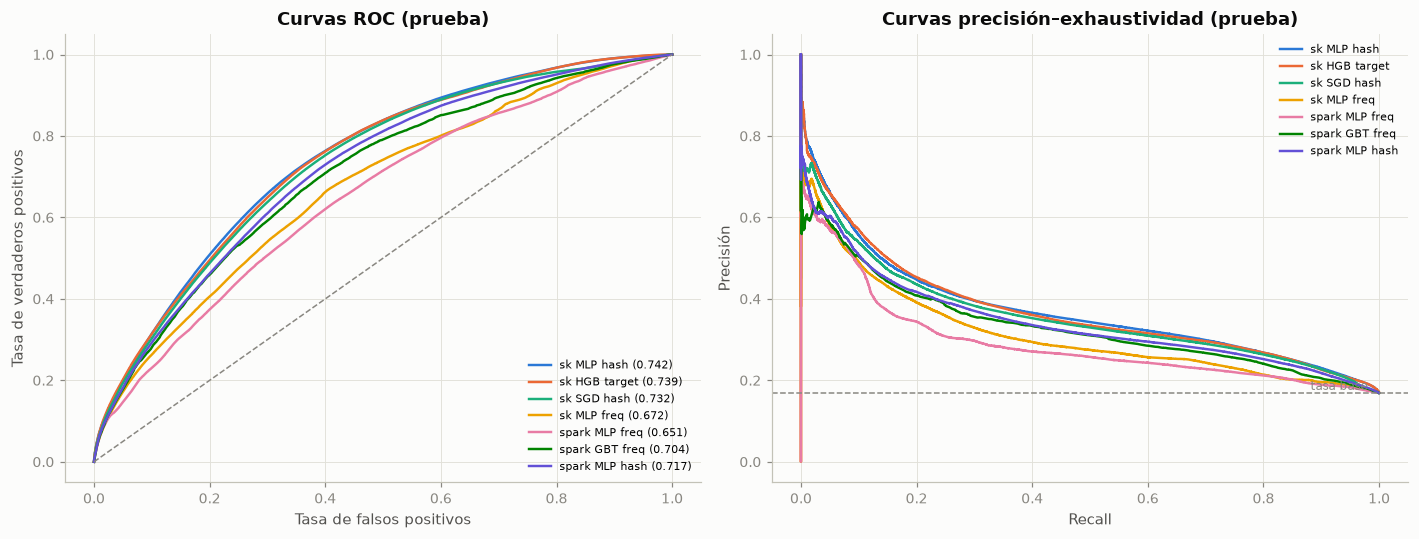

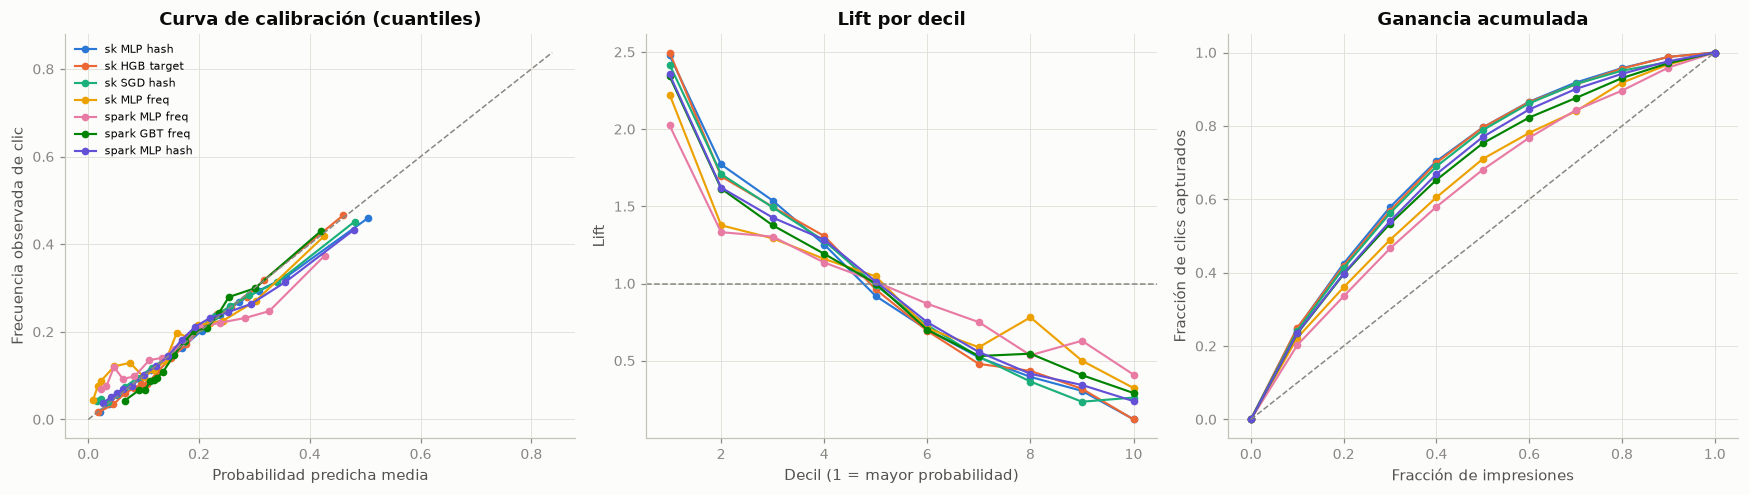

In [5]:
FOCO = ["sk MLP hash", "sk HGB target", "sk SGD hash", "sk MLP freq", "spark MLP freq", "spark GBT freq", "spark MLP hash"]
names = [k for k in FOCO if k in P] or list(P)[:8]   # curvas: hasta 7 modelos para que se lean
col = {k: SERIES[i % len(SERIES)] for i, k in enumerate(names)}
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for k in names:
    fpr, tpr, _ = roc_curve(yte, P[k]); axs[0].plot(fpr, tpr, color=col[k], linewidth=1.6, label=f"{k} ({M.all_metrics(yte, P[k], THR[k])['roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(yte, P[k]); axs[1].plot(rc, pr, color=col[k], linewidth=1.6, label=k)
axs[0].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
axs[1].axhline(yte.mean(), color=MUTED, linestyle="--", linewidth=1); axs[1].text(0.98, yte.mean(), "tasa base", ha="right", va="bottom", color=MUTED, fontsize=8)
axs[0].set(title="Curvas ROC (prueba)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
axs[1].set(title="Curvas precisión–exhaustividad (prueba)", xlabel="Recall", ylabel="Precisión")
axs[0].legend(fontsize=7, loc="lower right"); axs[1].legend(fontsize=7)
savefig(fig, FIG, "06_roc_pr")

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
for k in names:
    fr, mp = calibration_curve(yte, P[k], n_bins=15, strategy="quantile")
    axs[0].plot(mp, fr, marker="o", markersize=4, color=col[k], linewidth=1.4, label=k)
    lt = M.lift_table(yte, P[k])
    axs[1].plot(lt["decil"], lt["lift"], marker="o", markersize=4, color=col[k], linewidth=1.4, label=k)
    axs[2].plot(np.r_[0, lt["pct_poblacion"]], np.r_[0, lt["ganancia_acum"]], marker="o", markersize=4, color=col[k], linewidth=1.4, label=k)
mx = max(np.quantile(P[k], 0.999) for k in names)
axs[0].plot([0, mx], [0, mx], color=MUTED, linestyle="--", linewidth=1)
axs[0].set(title="Curva de calibración (cuantiles)", xlabel="Probabilidad predicha media", ylabel="Frecuencia observada de clic")
axs[1].axhline(1, color=MUTED, linestyle="--", linewidth=1); axs[1].set(title="Lift por decil", xlabel="Decil (1 = mayor probabilidad)", ylabel="Lift")
axs[2].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1); axs[2].set(title="Ganancia acumulada", xlabel="Fracción de impresiones", ylabel="Fracción de clics capturados")
axs[0].legend(fontsize=7)
savefig(fig, FIG, "06_calibracion_lift_ganancia")

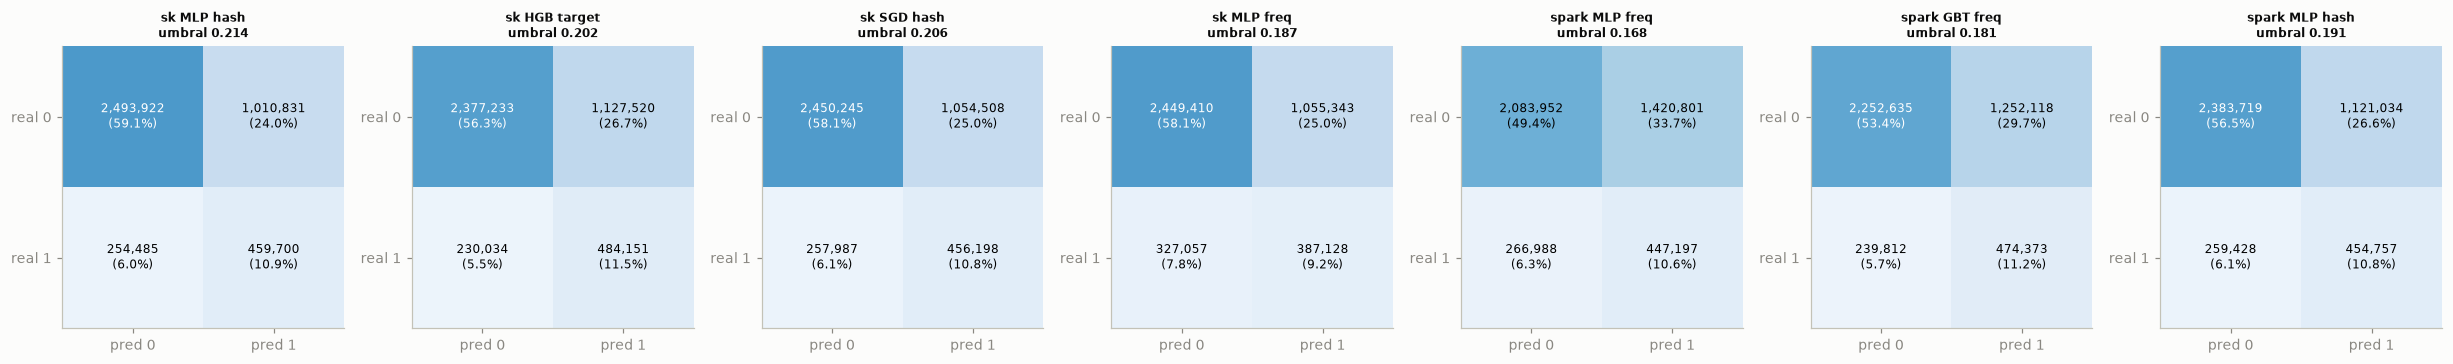

In [6]:
# matrices de confusión con el umbral elegido en validación
fig, axs = plt.subplots(1, len(names), figsize=(3.2 * len(names), 3.2), squeeze=False)
for ax, k in zip(axs[0], names):
    m = M.all_metrics(yte, P[k], THR[k])
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    ax.imshow(cm / cm.sum(), cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm.sum():.1%})", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] / cm.sum() > 0.5 else "black")
    ax.set_xticks([0, 1], ["pred 0", "pred 1"]); ax.set_yticks([0, 1], ["real 0", "real 1"])
    ax.set_title(f"{k}\numbral {THR[k]:.3f}", fontsize=8)
savefig(fig, FIG, "06_matrices_confusion")

## 6.5 Pruebas de hipótesis: DeLong (AUC) y McNemar (clasificaciones), con ajuste de Holm

In [7]:
pairs = [("sk MLP freq", "spark MLP freq"), ("sk MLP freq", "sk HGB freq"), ("sk MLP freq", "sk SGD freq"),
         ("spark MLP freq", "spark GBT freq"), ("spark MLP freq", "spark LR freq")]
pairs += [("sk MLP hash", "sk HGB target"), ("sk MLP hash", "sk SGD hash"), ("sk MLP hash", "sk MLP freq"),
          ("spark MLP hash", "spark LR hash"), ("sk MLP hash (mismo n que Spark)", "spark MLP hash")]
rows = []
for a, b in pairs:
    if a not in P or b not in P:
        continue
    d = M.delong_test(yte, P[a], P[b])
    mc = M.mcnemar_test(yte, P[a] >= THR[a], P[b] >= THR[b])
    rows.append({"A": a, "B": b, "AUC_A": d["auc1"], "AUC_B": d["auc2"], "dif_AUC": d["diff"], "EE": d["se"],
                 "z": d["z"], "p_DeLong": d["p_value"], "McNemar_b(A✓B✗)": mc["b"], "McNemar_c(A✗B✓)": mc["c"],
                 "p_McNemar": mc["p_value"]})
tests = pd.DataFrame(rows)
if len(tests):
    tests["p_DeLong_Holm"] = multipletests(tests["p_DeLong"], method="holm")[1]
    tests["p_McNemar_Holm"] = multipletests(tests["p_McNemar"], method="holm")[1]
tests.to_csv(RES / "pruebas_hipotesis.csv", index=False)
show(tests, 20, "{:.5f}")

,A,B,AUC_A,AUC_B,dif_AUC,EE,z,p_DeLong,McNemar_b(A✓B✗),McNemar_c(A✗B✓),p_McNemar,p_DeLong_Holm,p_McNemar_Holm
0,sk MLP freq,spark MLP freq,0.67172,0.65096,0.02077,0.00022,93.38425,0.00000,598833,293444,0.00000,0.00000,0.00000
1,sk MLP freq,sk HGB freq,0.67172,0.72510,-0.05338,0.00029,-181.99856,0.00000,424207,447457,0.00000,0.00000,0.00000
2,sk MLP freq,sk SGD freq,0.67172,0.64095,0.03077,0.00033,94.62391,0.00000,1249898,263456,0.00000,0.00000,0.00000
3,spark MLP freq,spark GBT freq,0.65096,0.70375,-0.05279,0.00031,-172.64230,0.00000,386817,582676,0.00000,0.00000,0.00000
4,spark MLP freq,spark LR freq,0.65096,0.63531,0.01565,0.00041,38.49667,0.00000,1149143,428586,0.00000,0.00000,0.00000
5,sk MLP hash,sk HGB target,0.74221,0.73910,0.00311,0.00015,21.30717,0.00000,237236,144998,0.00000,0.00000,0.00000
6,sk MLP hash,sk SGD hash,0.74221,0.73167,0.01054,0.00014,75.72761,0.00000,242353,195174,0.00000,0.00000,0.00000
7,sk MLP hash,sk MLP freq,0.74221,0.67172,0.07049,0.00029,243.86773,0.00000,531106,414022,0.00000,0.00000,0.00000
8,spark MLP hash,spark LR hash,0.71706,0.70877,0.00829,0.00015,54.60881,0.00000,194284,237112,0.00000,0.00000,0.00000
9,sk MLP hash (mismo n que Spark),spark MLP hash,0.71682,0.71706,-0.00023,0.00010,-2.40911,0.01599,236879,133472,0.00000,0.01599,0.00000


**Lectura correcta.** Con millones de filas de prueba, diferencias de AUC muy pequeñas resultan
"significativas". Por eso se reporta siempre la magnitud (`dif_AUC` e IC) junto al valor p, y se
discute si la diferencia importa en la práctica (por ejemplo, en el lift del primer decil).

## 6.6 Sin y con ponderación de clases

In [8]:
ab = read_jsonl(RES / "ablaciones_sklearn.jsonl")
pc = ab[ab["factor"] == "ponderacion_clases"].copy()
pc[["modelo", "ponderacion"]] = pc["nivel"].str.split(":", expand=True)
tab_pc = M.summarize_runs(pc, ["modelo", "ponderacion"], ["roc_auc", "log_loss", "ece", "mean_p", "precision", "recall", "f1"])
tab_pc.to_csv(RES / "tabla_ponderacion.csv", index=False)
show(tab_pc[["modelo", "ponderacion", "n_semillas", "roc_auc_media", "log_loss_media", "ece_media", "mean_p_media",
             "precision_media", "recall_media", "f1_media"]])
print("Esperable: la ponderación casi no cambia la AUC (es invariante al reescalado monótono), "
      "pero infla las probabilidades (mean_p >> tasa base), empeora log loss y ECE, y desplaza el "
      "equilibrio precisión/recall. Verifique si sus datos lo confirman.")

,modelo,ponderacion,n_semillas,roc_auc_media,log_loss_media,ece_media,mean_p_media,precision_media,recall_media,f1_media
0,hgb,balanced,3,0.7185,0.5860,0.2533,0.4226,0.2966,0.6321,0.4037
1,hgb,ninguna,3,0.7191,0.4108,0.0101,0.1778,0.2992,0.6321,0.4062
2,mlp,balanced,3,0.7266,0.5884,0.2589,0.4281,0.2943,0.6517,0.4055
3,mlp,ninguna,3,0.7295,0.4064,0.0084,0.1644,0.3011,0.6386,0.4093
4,sgd,balanced,3,0.7148,0.5790,0.2470,0.4163,0.2738,0.7051,0.3914
5,sgd,ninguna,3,0.7247,0.4090,0.0125,0.1693,0.2932,0.6536,0.4047


Esperable: la ponderación casi no cambia la AUC (es invariante al reescalado monótono), pero infla las probabilidades (mean_p >> tasa base), empeora log loss y ECE, y desplaza el equilibrio precisión/recall. Verifique si sus datos lo confirman.
